# **Job Market  Analysis and Recommendation System**

# **Load Dataset**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv("all_upwork_jobs.csv")
print(df.shape)

(244828, 8)


### **Insight: Dataset Shape**
* The dataset contains **244,828 job postings** and **8 columns** initially.
* This represents a massive pool of freelance jobs on Upwork, providing high statistical confidence for the analysis.

In [ ]:
df.head()

,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country
0,Experienced Media Buyer For Solar Pannel and R...,https://www.upwork.com/jobs/Experienced-Media-...,2024-02-17 09:09:54+00:00,False,NaN,NaN,500.0,NaN
1,Full Stack Developer,https://www.upwork.com/jobs/Full-Stack-Develop...,2024-02-17 09:09:17+00:00,False,NaN,NaN,1100.0,United States
2,SMMA Bubble App,https://www.upwork.com/jobs/SMMA-Bubble-App_%7...,2024-02-17 09:08:46+00:00,True,10.0,30.0,NaN,United States
3,Talent Hunter Specialized in Marketing,https://www.upwork.com/jobs/Talent-Hunter-Spec...,2024-02-17 09:08:08+00:00,True,NaN,NaN,NaN,United States
4,Data Engineer,https://www.upwork.com/jobs/Data-Engineer_%7E0...,2024-02-17 09:07:42+00:00,False,NaN,NaN,650.0,India


### **Insight: First Rows of the Dataset**
* The initial preview reveals key attributes such as job `title`, the original Upwork job `link`, and binary flag `is_hourly` indicating contract types.
* Features like `hourly_low`, `hourly_high`, and `budget` contain selective values depending on the payment structures.

In [ ]:
df.tail()

,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country
244823,Need Facebook advertising experts to launch pr...,https://www.upwork.com/jobs/Need-Facebook-adve...,2024-03-24 13:28:38+00:00,True,20.0,100.0,NaN,Zambia
244824,Digital/Telemarketing/Sales/OutSide Sales,https://www.upwork.com/jobs/Digital-Telemarket...,2024-03-24 13:40:52+00:00,False,NaN,NaN,100.0,Sri Lanka
244825,WordPress Template Edits,https://www.upwork.com/jobs/WordPress-Template...,2024-03-24 13:37:50+00:00,True,5.0,30.0,NaN,United States
244826,ELEMENTOR PRO For quick fix (Wordpress),https://www.upwork.com/jobs/ELEMENTOR-PRO-For-...,2024-03-24 13:52:15+00:00,False,NaN,NaN,15.0,France
244827,Creating a UGC Ad for Our Mobile Game,https://www.upwork.com/jobs/Creating-UGC-for-O...,2024-03-24 13:53:00+00:00,False,NaN,NaN,50.0,Israel


### **Insight: Final Rows of the Dataset**
* The bottom tail rows confirm that the data captures global jobs, featuring countries like Zambia, Sri Lanka, France, and Israel.
* The timestamp entries verify structured date values across multiple months.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244828 entries, 0 to 244827
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   title           244827 non-null  object 
 1   link            244827 non-null  object 
 2   published_date  244828 non-null  object 
 3   is_hourly       244828 non-null  bool   
 4   hourly_low      102422 non-null  float64
 5   hourly_high     98775 non-null   float64
 6   budget          103891 non-null  float64
 7   country         239751 non-null  object 
dtypes: bool(1), float64(3), object(4)
memory usage: 13.3+ MB


### **Insight: Data Types & Missing Values**
* Out of 244,828 rows, features like `hourly_low`, `hourly_high`, and `budget` contain more than **140,000 null values** because jobs are mutually exclusive (hourly jobs don't have a fixed budget, and fixed-price jobs do not have hourly rates).
* There is only 1 missing value in `title` and `link` which can be easily dropped.

In [ ]:
df.describe()

,hourly_low,hourly_high,budget
count,102422.000000,98775.000000,103891.000000
mean,17.339644,41.970610,911.473564
std,18.140065,47.850892,15729.738834
min,3.000000,3.000000,5.000000
25%,8.000000,20.000000,25.000000
50%,15.000000,30.000000,100.000000
75%,20.000000,50.000000,300.000000
max,998.000000,999.000000,1000000.000000


# **Check Duplicate & Missing Values**

In [ ]:
df.isnull().sum()

,0
title,1
link,1
published_date,0
is_hourly,0
hourly_low,142406
hourly_high,146053
budget,140937
country,5077


### **Insight: Missing Values Status**
* Key financial metrics (`hourly_low`, `hourly_high`, `budget`) hold over **57% missing values** due to mutual exclusivity between Hourly and Fixed-Price jobs.
* There are also **5,077 postings** lacking country details, which represents a tiny percentage of the overall dataset.

In [ ]:
df.duplicated().sum()

np.int64(0)

### **Insight: Dataset Duplicates**
* The duplication check yielded a value of **0**, meaning there are no duplicate job records in the dataset.
* This guarantees the integrity of subsequent statistical and machine learning models.

# **Handle Missing value**

In [ ]:
df["published_date"] = pd.to_datetime(df["published_date"], errors='coerce')

In [ ]:
df.dropna(subset=['title','link'], inplace=True)

In [ ]:
df['hourly_low'] = df['hourly_low'].fillna(0)
df['hourly_high'] = df['hourly_high'].fillna(0)
df['budget'] = df['budget'].fillna(0)


In [ ]:
df['country'] = df['country'].fillna('Other_Country')

In [ ]:
median_low_by_country = df[(df['is_hourly'] == True) & (df['hourly_low'] > 0)].groupby('country')['hourly_low'].median()
median_high_by_country = df[(df['is_hourly'] == True) & (df['hourly_high'] > 0)].groupby('country')['hourly_high'].median()

global_low_median = df[(df['is_hourly'] == True) & (df['hourly_low'] > 0)]['hourly_low'].median()
global_high_median = df[(df['is_hourly'] == True) & (df['hourly_high'] > 0)]['hourly_high'].median()

df['hourly_low'] = df.apply(
    lambda row: median_low_by_country.get(row['country'], global_low_median)
    if row['is_hourly'] == True and row['hourly_low'] == 0
    else row['hourly_low'], axis=1
)

df['hourly_high'] = df.apply(
    lambda row: median_high_by_country.get(row['country'], global_high_median)
    if row['is_hourly'] == True and row['hourly_high'] == 0
    else row['hourly_high'], axis=1
)

### **Insight: Handling Missing Values & Contextual Imputation**
* **Standardized Timestamps**: Convert `published_date` to pandas datetime format (`errors='coerce'`) to enable temporal indexing and seamless date calculations.
* **Essential Rows Retained**: We dropped rows with missing `title` and `link` as they constitute the target text features for our similarity models, and represent negligible data loss (1 record).
* **Mutually Exclusive Handling**: Set missing values in `hourly_low`, `hourly_high`, and `budget` to `0` initially because hourly and fixed-budget listings do not share financial metrics.
* **Advanced Group Imputation**: To avoid skewing data with flat global averages, we imputed missing hourly limits (`hourly_low`, `hourly_high`) using the **median of the client's home country**. If a country profile is missing entirely, the global platform median is used as a fallback strategy.

# **Step 4: Create New Features**

In [ ]:
df['avg_hourly_rate'] = (
    df['hourly_low'] +
    df['hourly_high']
)/2

In [ ]:
df['year'] = df['published_date'].dt.year

In [ ]:
df['month'] = df['published_date'].dt.month

In [ ]:
df['month_name'] = df['published_date'].dt.month_name()

### **Insight: Feature Engineering**
* Created custom features: `avg_hourly_rate` (midpoint rate), and date-based parameters (`year`, `month`, `month_name`).
* These new features simplify trend calculations and provide clear variables for prediction algorithms.

## **Text Preprocessing & Keyword Extraction**

In [ ]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt_tab')

lemmatizer = WordNetLemmatizer()
def extract_keywords(title):
  if pd.isna(title):
    return []

  title = str(title).lower()
  title = re.sub(r'[^a-zA-Z\s]', '', title)

  tokens = word_tokenize(title)

  stop_words = set(stopwords.words('english'))
  keywords = [
      lemmatizer.lemmatize(token)
      for token in tokens
      if token not in stop_words and len(token) > 1
  ]

  return keywords


df['clean_keywords'] = df['title'].apply(extract_keywords)



[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


## **Most Frequent Keyword Analysis**

In [ ]:
from collections import Counter

all_keywords = [
    word for sublist in df['clean_keywords'].dropna() for word in sublist
]

keyword_counts = Counter(all_keywords)

for word, count in keyword_counts.most_common(20):
  print(f'{word} --> {count}')

website --> 17571
needed --> 17570
video --> 16191
developer --> 15998
expert --> 15251
design --> 13513
designer --> 12839
need --> 10609
amp --> 9277
specialist --> 9047
looking --> 8730
medium --> 8251
marketing --> 8250
app --> 8094
editor --> 7964
youtube --> 7585
social --> 7580
ad --> 7316
data --> 7038
manager --> 6838


### **Insight: Keyword Frequency**
* High-frequency terms such as **'website'**, **'video'**, **'developer'**, **'expert'**, **'design'**, and **'editor'** highlight the predominant sectors of work on Upwork.
* Web Development, Video Editing, and Graphic Designing are currently the most active job niches.

## **Splitting Data into Hourly and Fixes-Price Jobs**

In [ ]:
hourly_df = df[df['is_hourly'] == True].copy()
fixed_df = df[df['is_hourly'] == False].copy()

# **Exploratory Data Analysis**
## **Univariate Analysis**

### **Hourly vs Fixed Price job**

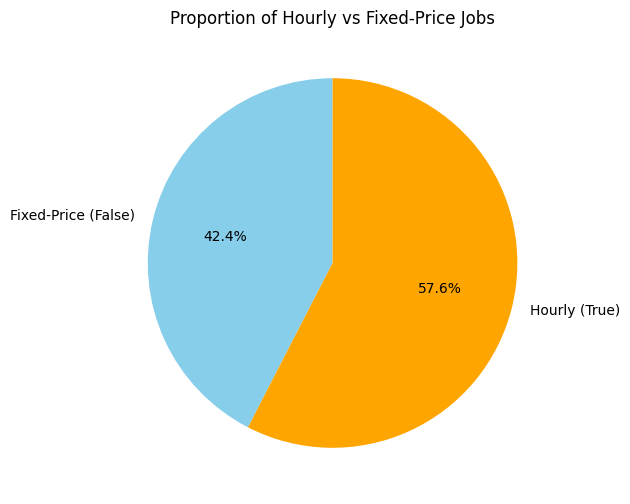

,count
is_hourly,
True,140936
False,103891


In [ ]:
is_hourly_counts = df['is_hourly'].value_counts().sort_index()

plt.figure(figsize=(6, 6))
plt.pie(
    is_hourly_counts,
    labels=['Fixed-Price (False)', 'Hourly (True)'],
    autopct='%1.1f%%',
    colors=['skyblue', 'orange'],
    startangle=90,
)
plt.title('Proportion of Hourly vs Fixed-Price Jobs')
plt.show()
df['is_hourly'].value_counts()

### **Insight: Hourly vs Fixed-Price Distribution**
* Around **57.6%** of jobs on Upwork are **Hourly-based**, while **42.4%** are **Fixed-Price** projects.
* Freelancers looking for long-term consistency may find more opportunities in the Hourly category.

## **Top 10 Countries by job posting**

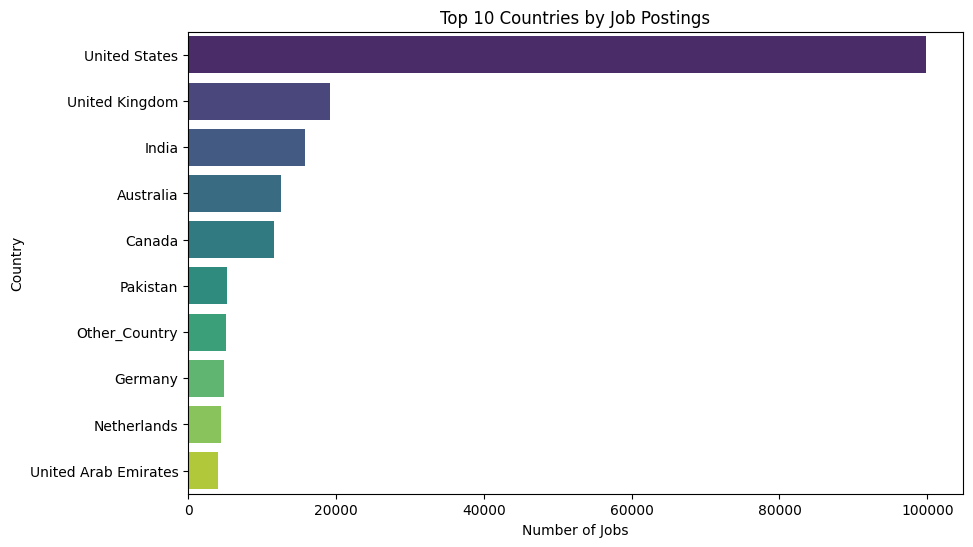

In [ ]:
plt.figure(figsize=(10, 6))
top_countries = df['country'].value_counts().head(10)
sns.barplot(x=top_countries.values, y=top_countries.index, palette='viridis')
plt.title('Top 10 Countries by Job Postings')
plt.xlabel('Number of Jobs')
plt.ylabel('Country')
plt.show()

### **Insight: Top Countries by Job Postings**
* The **United States** is by far the leading source of freelance job postings, followed by the **United Kingdom**, **India**, **Australia**, and **Canada**.
* Western markets dominate the buyer side of the Upwork platform.

### **Hourly Rate Distribution**


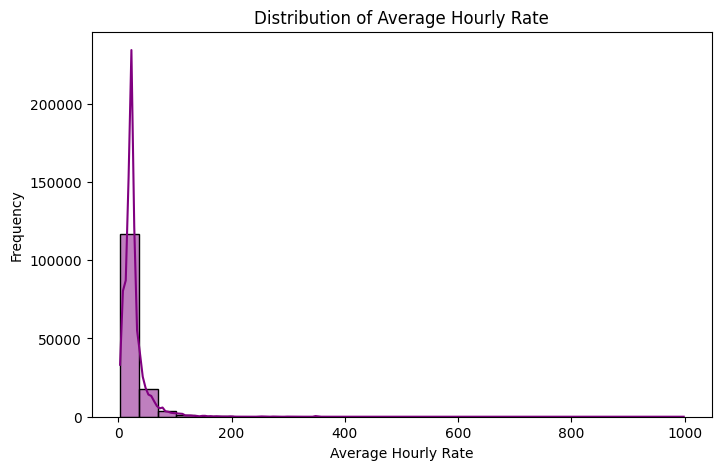

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(
    hourly_df['avg_hourly_rate'], kde=True, color='purple', bins=30
)
plt.title('Distribution of Average Hourly Rate')
plt.xlabel('Average Hourly Rate')
plt.ylabel('Frequency')
plt.show()

### **Insight: Hourly Rate Distribution**
* The distribution of average hourly rates is heavily right-skewed.
* The vast majority of hourly jobs offer rates under **$50/hour**, with a very high concentration (peak) between **$10 and $30/hour**.

### **Outlier Detection in Hourly Rates**


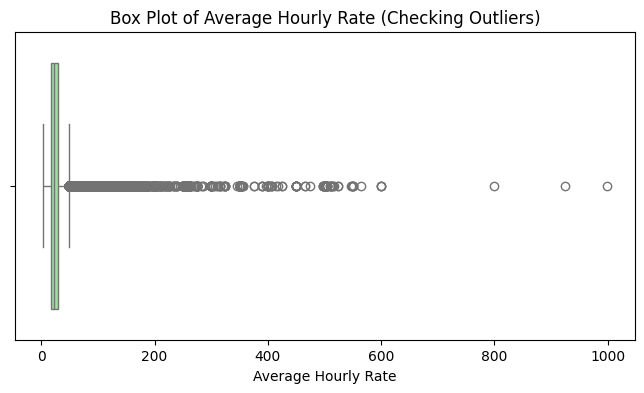

In [ ]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=hourly_df['avg_hourly_rate'], color='lightgreen')
plt.title('Box Plot of Average Hourly Rate (Checking Outliers)')
plt.xlabel('Average Hourly Rate')
plt.show()

### **Insight: Outlier Detection in Hourly Rates**
* The box plot confirms the presence of extreme outliers on the higher end of the hourly spectrum, reaching up to **$1000/hour**.
* While standard rates remain highly concentrated, high-end specialist consulting jobs represent anomalous premium hourly rates.

# **Bivariate Analysis**
## **Top Keywords vs Hourly Jobs**

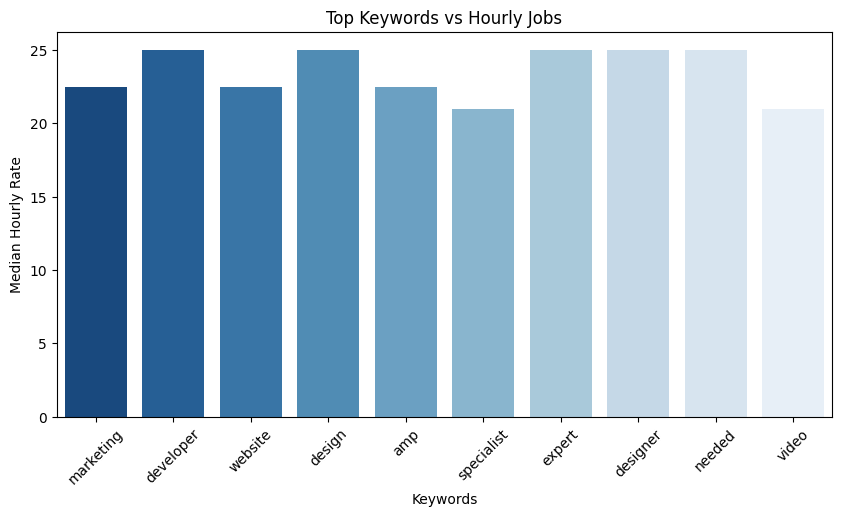

--- Hourly Jobs: Top Keywords & Rates Summary Table ---


,keyword,avg_hourly_rate
1,design,25.0
2,designer,25.0
4,expert,25.0
3,developer,25.0
6,needed,25.0
0,amp,22.5
5,marketing,22.5
9,website,22.5
7,specialist,21.0
8,video,21.0


In [ ]:
hourly_keywords_list = []
for idx, row in hourly_df.iterrows():
  if isinstance(row['clean_keywords'], list):
    for word in row['clean_keywords']:
      hourly_keywords_list.append(
          {'keyword': word, 'avg_hourly_rate': row['avg_hourly_rate']}
      )

df_hourly_kw = pd.DataFrame(hourly_keywords_list)

top10_hourly_words = df_hourly_kw['keyword'].value_counts().head(10).index
df_top10_hourly = df_hourly_kw[
    df_hourly_kw['keyword'].isin(top10_hourly_words)
]

plt.figure(figsize=(10, 5))
sns.barplot(
    data=df_top10_hourly,
    x='keyword',
    y='avg_hourly_rate',
    estimator='median',
    ci=None,
    palette='Blues_r',
)
plt.title('Top Keywords vs Hourly Jobs')
plt.xlabel('Keywords')
plt.ylabel('Median Hourly Rate')
plt.xticks(rotation=45)
plt.show()


table_hourly = (
    df_top10_hourly.groupby('keyword')['avg_hourly_rate']
    .median()
    .reset_index()
)

table_hourly['avg_hourly_rate'] = table_hourly['avg_hourly_rate'].round(2)
table_hourly = table_hourly.sort_values(
    by='avg_hourly_rate', ascending=False
)

print('--- Hourly Jobs: Top Keywords & Rates Summary Table ---')
display(table_hourly)


### **Insight: Hourly Job Rates by Keywords**
* Jobs targeting keywords like **'developer'**, **'design'**, **'expert'**, and **'designer'** enjoy higher median hourly rates of around **$25.00**.
* Specialized technical and creative roles are compensated better compared to generic tasks.

## **Top Keywords vs Fixed-Price Jobs**

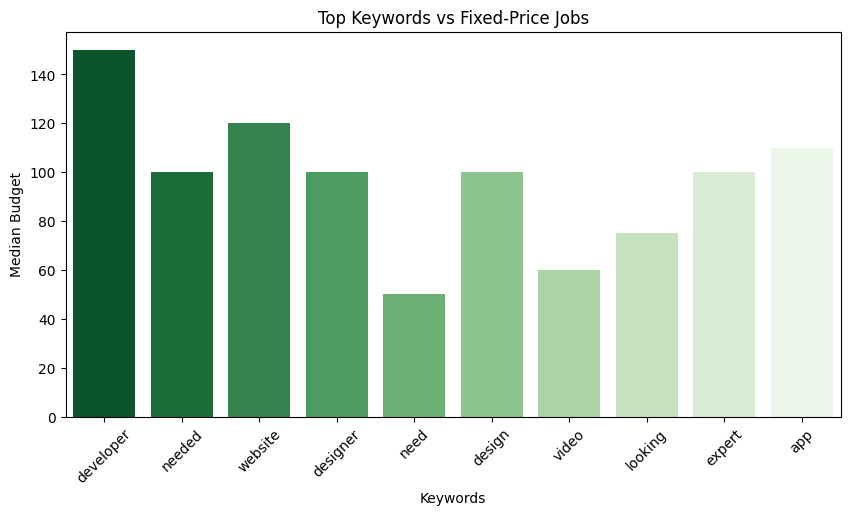

--- Fixed-Price Jobs: Top Keywords & Budget Summary Table ---


,keyword,budget
3,developer,150.0
9,website,120.0
0,app,110.0
1,design,100.0
4,expert,100.0
2,designer,100.0
7,needed,100.0
5,looking,75.0
8,video,60.0
6,need,50.0


In [ ]:
fixed_keywords_list = []
for idx, row in fixed_df.iterrows():
  if isinstance(row['clean_keywords'], list):
    for word in row['clean_keywords']:
      fixed_keywords_list.append(
          {'keyword': word, 'budget': row['budget']}
      )

df_fixed_kw = pd.DataFrame(fixed_keywords_list)

top10_fixed_words = df_fixed_kw['keyword'].value_counts().head(10).index
df_top10_fixed = df_fixed_kw[df_fixed_kw['keyword'].isin(top10_fixed_words)]

plt.figure(figsize=(10, 5))
sns.barplot(
    data=df_top10_fixed,
    x='keyword',
    y='budget',
    estimator='median',
    ci=None,
    palette='Greens_r',
)
plt.title('Top Keywords vs Fixed-Price Jobs')
plt.xlabel('Keywords')
plt.ylabel('Median Budget')
plt.xticks(rotation=45)
plt.show()


table_fixed = (
    df_top10_fixed.groupby('keyword')['budget'].median().reset_index()
)

table_fixed['budget'] = table_fixed['budget'].round(2)

table_fixed = table_fixed.sort_values(by='budget', ascending=False)

print('--- Fixed-Price Jobs: Top Keywords & Budget Summary Table ---')
display(table_fixed)

### **Insight: Fixed-Price Budgets by Keywords**
* **'developer'** profiles command the highest median fixed-price budget of **$150**, followed closely by **'website'** at **$120** and **'app'** at **$110**.
* Custom web and mobile application development represent high-ticket projects.

## **Monthly Job Trend**

In [ ]:
df['year_month'] = (
    df['published_date']
    .dt.to_period('M')
)

### **Insight: Monthly Period Feature**
* Created a new feature `year_month` by converting the `published_date` column into monthly periods.
* This period feature allows for smooth chronological grouping and tracking monthly job posting volumes.

## **Top 10 Job Titles**

In [ ]:
top_jobs = df['title'].value_counts().head(10)

print(top_jobs)

title
Social Media Manager    419
Virtual Assistant       339
Logo Design             311
Video Editor            298
Graphic Designer        292
Logo design             173
Logo Designer           142
Full Stack Developer    136
Website Development     129
Appointment Setter      125
Name: count, dtype: int64


### **Insight: Most Common Job Titles**
* Generalist and creative administrative roles like **'Social Media Manager'**, **'Virtual Assistant'**, and **'Logo Design'** are the absolute most frequent exact titles posted on Upwork.
* This shows a very high volume of recurring, standard tasks in marketing, administrative support, and graphic design.

## **Monthly Posting Trend**

In [ ]:
monthly_jobs = (
    df.groupby('year_month')
    .size()
    .reset_index(name='job_count')
)

### **Insight: Monthly Aggregation Prep**
* Grouped the entire dataset by the custom `year_month` column to calculate the exact frequency of jobs per month.
* This prepared aggregated series serves as the primary input for evaluating historical platform growth and training trend forecasting models.

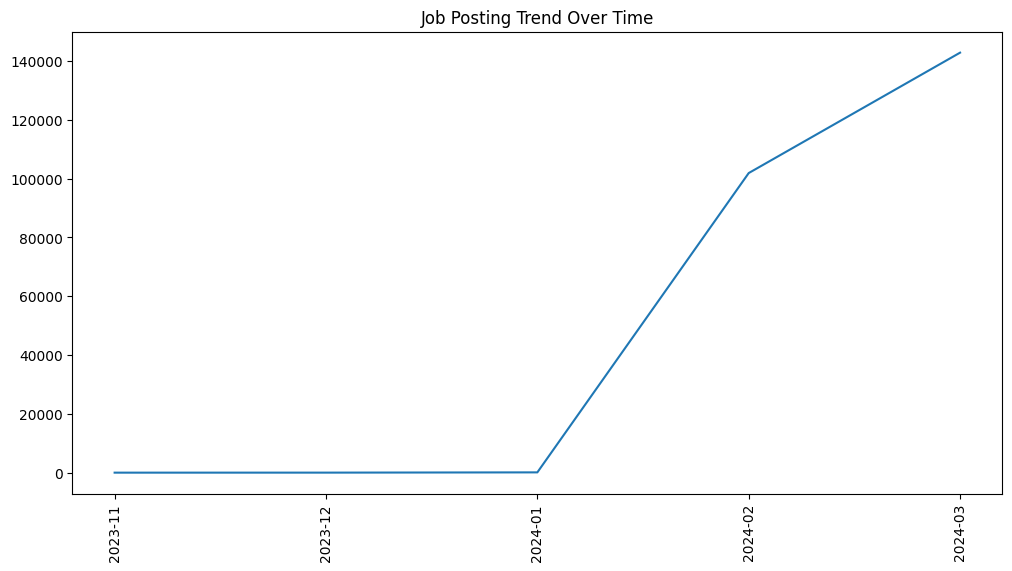

In [ ]:
plt.figure(figsize=(12,6))

plt.plot(
    monthly_jobs['year_month'].astype(str),
    monthly_jobs['job_count']
)

plt.xticks(rotation=90)

plt.title("Job Posting Trend Over Time")

plt.show()

### **Insight: Timeline Posting Trend**
* There is a massive spike in job postings starting from **January 2024** onwards.
* The data shows a shift from low/dormant activity in late 2023 to highly active posting periods in early 2024, indicating potential platform seasonality or data collection patterns.

## **Top Emerging Job Categories**

--- Top Growing Jobs by Volume (Absolute Growth) ---


,year_month,title,job_count,growth_count
197716,2024-03,Video Editor,202,106.0
148139,2024-03,Logo Design,201,91.0
186543,2024-03,Social Media Manager,245,71.0
134858,2024-03,Graphic Designer,172,52.0
146101,2024-03,Lead Generation,83,45.0
126495,2024-03,Facebook ads manager,53,40.0
80468,2024-02,Virtual assistant,36,35.0
148380,2024-03,Logo Designer,88,34.0
92275,2024-03,Actualmente estamos contratando hispanohablant...,43,33.0
135778,2024-03,Graphic designer,52,29.0


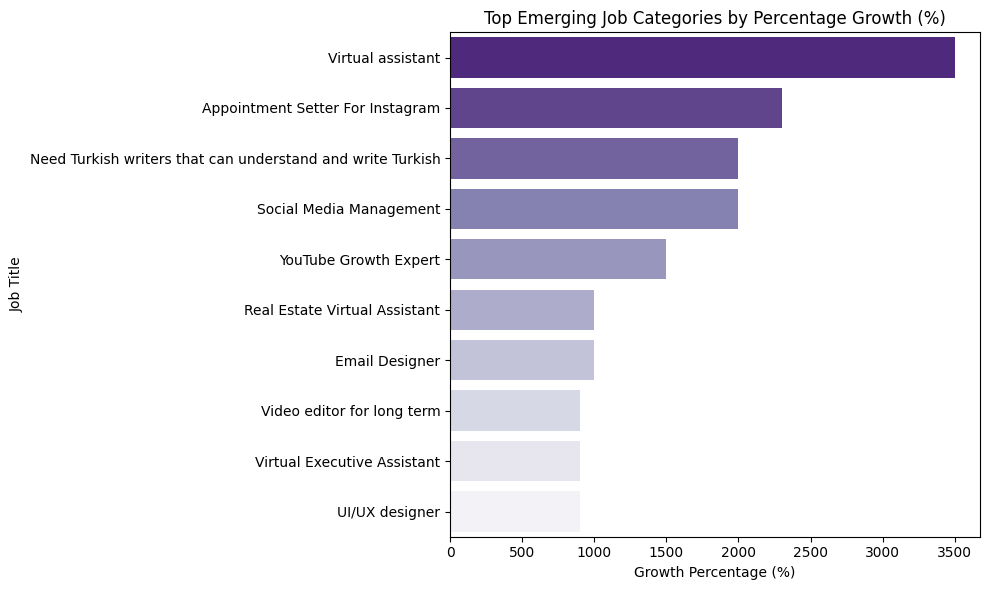

In [ ]:
monthly_job_counts = (
    df.groupby(['year_month', 'title']).size().reset_index(name='job_count')
)

monthly_job_counts['growth_count'] = monthly_job_counts.groupby('title')[
    'job_count'
].diff()

print('--- Top Growing Jobs by Volume (Absolute Growth) ---')
display(
    monthly_job_counts.dropna()
    .sort_values(by='growth_count', ascending=False)
    .head(10)
)

# Monthly count per title
job_growth_df = (
    df.groupby(['year_month', 'title'])
      .size()
      .reset_index(name='count')
)

# Percentage growth
job_growth_df['growth_percentage'] = (
    job_growth_df.groupby('title')['count']
    .pct_change() * 100
)

job_growth_df['growth_percentage'] = (
    job_growth_df['growth_percentage']
    .round(2)
)

# Filter very small counts
job_growth_df = job_growth_df[
    job_growth_df['count'] >= 10
]

# Top 10 emerging jobs
top_growth = (
    job_growth_df
    .dropna()
    .sort_values(
        by='growth_percentage',
        ascending=False
    )
    .head(10)
)

plt.figure(figsize=(10,6))

sns.barplot(
    data=top_growth,
    y='title',
    x='growth_percentage',
    palette='Purples_r'
)

plt.title('Top Emerging Job Categories by Percentage Growth (%)')
plt.xlabel('Growth Percentage (%)')
plt.ylabel('Job Title')

plt.tight_layout()
plt.show()

### **Insight: Top Emerging Job Categories**
* Based on the percentage growth, specific roles have experienced massive spikes in monthly demand.
* Roles targeting specialized niches represent the highest relative growth compared to their baseline volume in earlier months.

## **Top Job Roles: Month-wise Hiring Demand Analysis**

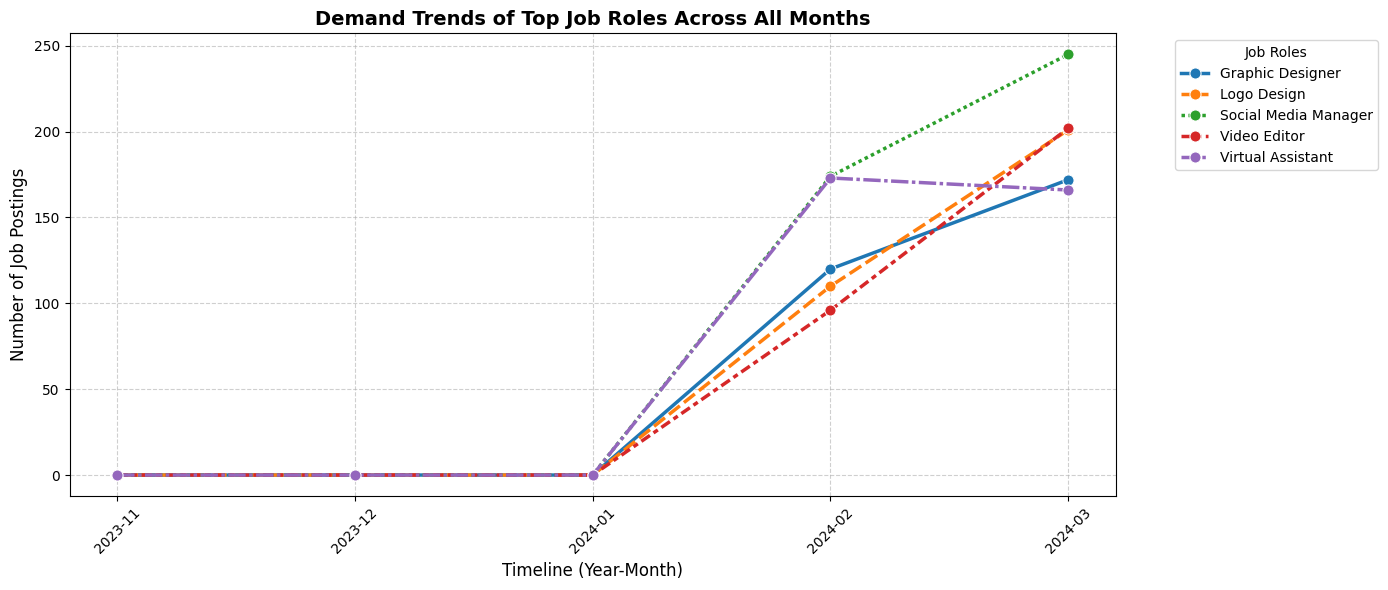

In [ ]:
all_months = sorted(df['year_month'].unique())

top_titles = df['title'].value_counts().head(5).index
df_filtered = df[df['title'].isin(top_titles)]

trend_pivot = (
    df_filtered.groupby(['year_month', 'title'])
    .size()
    .unstack(fill_value=0)
)

trend_pivot = trend_pivot.reindex(all_months, fill_value=0)

trend_pivot.index = trend_pivot.index.astype(str)

plt.figure(figsize=(14, 6))
ax = sns.lineplot(
    data=trend_pivot, marker='o', markersize=8, linewidth=2.5
)

plt.title(
    'Demand Trends of Top Job Roles Across All Months',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Timeline (Year-Month)', fontsize=12)
plt.ylabel('Number of Job Postings', fontsize=12)
plt.xticks(
    ticks=range(len(trend_pivot.index)),
    labels=trend_pivot.index,
    rotation=45,
)
plt.legend(title='Job Roles', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### **Insight: Demand Trends of Top Job Roles**
* The timeline plot shows a uniform growth pattern starting in **January 2024** for all 5 top job roles.
* **Social Media Manager** has maintained the highest trajectory of job postings overall, closely followed by **Video Editor** and **Graphic Designer**.

# **Average Hourly Rate by Country**

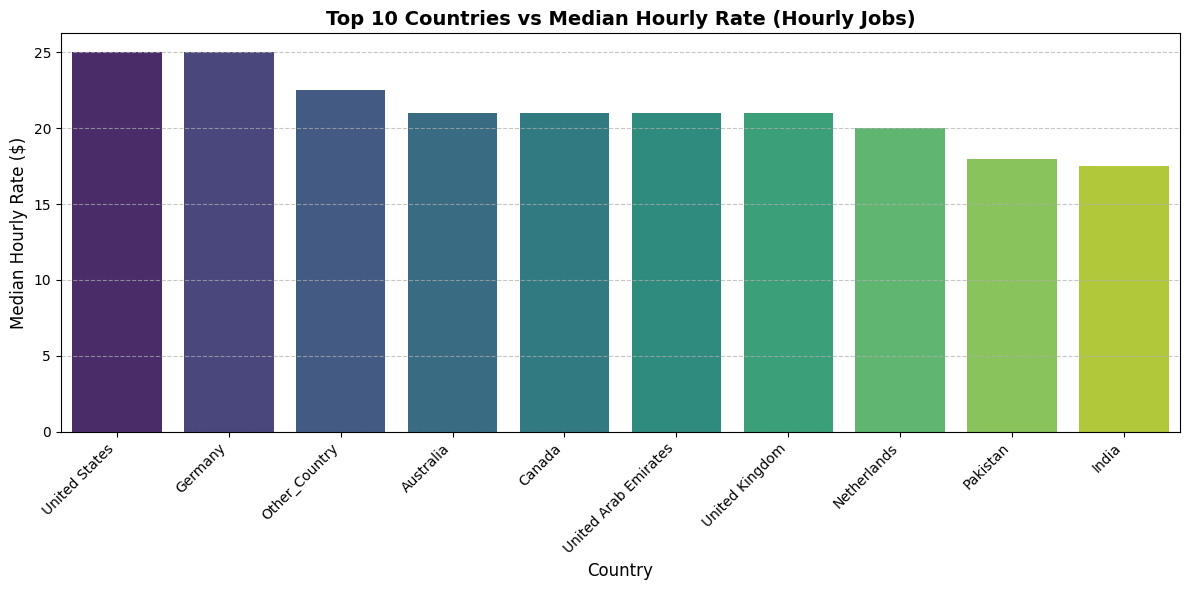

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

country_rates = (
    hourly_df.groupby('country')['avg_hourly_rate']
    .median()
    .reset_index()
)

top_countries = hourly_df['country'].value_counts().head(10).index
df_top_country_rates = country_rates[
    country_rates['country'].isin(top_countries)
]

df_top_country_rates = df_top_country_rates.sort_values(
    by='avg_hourly_rate', ascending=False
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_top_country_rates,
    x='country',
    y='avg_hourly_rate',
    palette='viridis',
)

plt.title(
    'Top 10 Countries vs Median Hourly Rate (Hourly Jobs)',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Median Hourly Rate ($)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()



### **Insight: Top Countries by Median Hourly Rate**
* Clients from the **United States** and **Germany** offer the highest median hourly rate of **$25.00**.
* Developing countries like **India** and **Pakistan** reside on the lower end with median hourly rates of **$17.50** and **$18.00** respectively.

# **Average Budget by Country (Fixed-Price Jobs)**


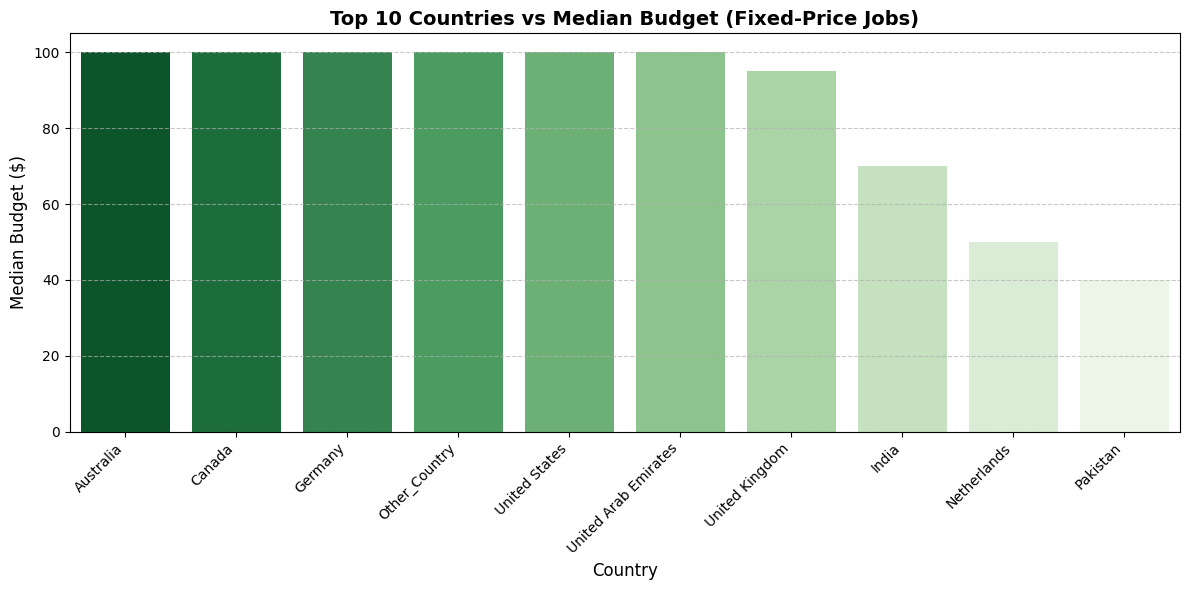

In [ ]:
country_fixed_budget = (
    fixed_df.groupby('country')['budget']
    .median()
    .reset_index()
)

top_fixed_countries = fixed_df['country'].value_counts().head(10).index
df_top_fixed_budget = country_fixed_budget[
    country_fixed_budget['country'].isin(top_fixed_countries)
]

df_top_fixed_budget = df_top_fixed_budget.sort_values(
    by='budget', ascending=False
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_top_fixed_budget, x='country', y='budget', palette='Greens_r'
)

plt.title(
    'Top 10 Countries vs Median Budget (Fixed-Price Jobs)',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Median Budget ($)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### **Insight: Top Countries by Median Fixed-Price Budget**
* For fixed-price contracts, countries like **Australia, Canada, Germany, the United States, and UAE** share a uniform top-tier median budget of **$100** per project.
* Clients from **Pakistan** and **Netherlands** offer lower median project budgets ranging from **$40 to $50**.

# **Investigate Trends in the Remote work Landscape**

In [ ]:
# 1.
if 'df' in globals() and isinstance(df, pd.DataFrame):
    t7_df = df.copy()
elif 'data' in globals() and isinstance(data, pd.DataFrame):
    t7_df = data.copy()
elif 'jobs_df' in globals() and isinstance(jobs_df, pd.DataFrame):
    t7_df = jobs_df.copy()
else:
    raise NameError("DataFrame का नाम नहीं मिला। कृपया पहली लाइन में t7_df = आपका_dataframe_नाम.copy() लिखें।")


col_map = {c.strip().lower().replace(' ', '_'): c for c in t7_df.columns}

def get_col(candidates):
    for cand in candidates:
        if cand in col_map:
            return col_map[cand]
    return None

title_col = get_col(['title', 'job_title', 'clean_title'])
country_col = get_col(['country', 'location'])
date_col = get_col(['date', 'posted_date', 'created_date', 'timestamp', 'month', 'year_month'])
low_col = get_col(['hourly_low', 'hourlylow', 'min_hourly'])
high_col = get_col(['hourly_high', 'hourlyhigh', 'max_hourly'])
avg_rate_col = get_col(['avg_hourly_rate', 'average_hourly_rate', 'hourly_rate', 'hourly_avg'])
budget_col = get_col(['budget', 'fixed_budget'])

# 2.
search_text = t7_df[title_col].fillna('').astype(str)
link_col = get_col(['link', 'url'])
if link_col:
    search_text = search_text + ' ' + t7_df[link_col].fillna('').astype(str)

def classify_work_mode(text):
    t = text.lower()
    if 'hybrid' in t:
        return 'Hybrid'
    elif any(k in t for k in ['remote', 'work from home', 'wfh', 'work-from-home', 'telecommute', 'anywhere']):
        return 'Remote'
    else:
        return 'Onsite / Office'

t7_df['Work_Mode'] = search_text.apply(classify_work_mode)

print("--- 1. Work Mode Distribution (Job Counts & Percentage) ---")
mode_summary = t7_df['Work_Mode'].value_counts().to_frame('Job_Count')
mode_summary['Percentage (%)'] = (mode_summary['Job_Count'] / len(t7_df) * 100).round(2)
print(mode_summary)
print("\n")

# 3.
if avg_rate_col:
    t7_df['Calc_Hourly_Rate'] = pd.to_numeric(t7_df[avg_rate_col], errors='coerce')
elif low_col and high_col:
    low_val = pd.to_numeric(t7_df[low_col], errors='coerce')
    high_val = pd.to_numeric(t7_df[high_col], errors='coerce')
    t7_df['Calc_Hourly_Rate'] = (low_val + high_val) / 2
else:
    t7_df['Calc_Hourly_Rate'] = np.nan

if budget_col:
    t7_df['Calc_Budget'] = pd.to_numeric(t7_df[budget_col], errors='coerce')
else:
    t7_df['Calc_Budget'] = np.nan

print("--- 2. Average Hourly Rate and Budget by Work Mode ---")
pay_summary = t7_df.groupby('Work_Mode')[['Calc_Hourly_Rate', 'Calc_Budget']].agg(['count', 'mean', 'median']).round(2)
print(pay_summary)
print("\n")

# 4.
if country_col:
    remote_only = t7_df[t7_df['Work_Mode'].isin(['Remote', 'Hybrid'])]
    print("--- 3. Top 10 Countries by Remote/Hybrid job Count ---")
    top_remote_countries = remote_only[country_col].fillna('Unknown').value_counts().head(10)
    print(top_remote_countries)
    print("\n")

# 5.
has_time_trend = False
trend_df = pd.DataFrame()

if date_col:
    raw_dates = t7_df[date_col].astype(str).str.strip()
    parsed = pd.to_datetime(raw_dates, errors='coerce')

    if parsed.notna().sum() < len(t7_df) * 0.2:
        parsed_alt = pd.to_datetime(raw_dates, errors='coerce', dayfirst=True)
        if parsed_alt.notna().sum() > parsed.notna().sum():
            parsed = parsed_alt

    valid_dates = t7_df.loc[parsed.notna()].copy()
    valid_dates['Parsed_Date'] = parsed.loc[parsed.notna()]
    print("---4. Remote job Trend Over Time ---")
    print(f"Total Valid dates found: {len(valid_dates)} / {len(t7_df)}")

    if len(valid_dates) > 1:
        if valid_dates['Parsed_Date'].dt.to_period('M').nunique() > 1:
            valid_dates['Period'] = valid_dates['Parsed_Date'].dt.to_period('M').astype(str)
        else:
            valid_dates['Period'] = valid_dates['Parsed_Date'].dt.date.astype(str)

        trend_df = valid_dates.groupby(['Period', 'Work_Mode']).size().unstack(fill_value=0)
        if trend_df.shape[0] > 1 and 'Remote' in trend_df.columns:
            has_time_trend = True

            print(trend_df.tail(10))
            print("\n")



--- 1. Work Mode Distribution (Job Counts & Percentage) ---
                 Job_Count  Percentage (%)
Work_Mode                                 
Onsite / Office     243361           99.40
Remote                1402            0.57
Hybrid                  64            0.03


--- 2. Average Hourly Rate and Budget by Work Mode ---
                Calc_Hourly_Rate               Calc_Budget               
                           count   mean median       count    mean median
Work_Mode                                                                
Hybrid                        64  17.86    6.0          64  565.39    0.0
Onsite / Office           243361  15.84   11.0      243361  386.05    0.0
Remote                      1402  26.18   20.5        1402  505.35    0.0


--- 3. Top 10 Countries by Remote/Hybrid job Count ---
country
United States     910
India              74
United Kingdom     60
Australia          43
Canada             34
Other_Country      30
Philippines        24
Nethe

### **Insight: Remote Work Classification & Financial Overview**
* **Extreme Concentration of Office/Onsite Postings**: The vast majority of postings (**99.40%**) do not explicitly mention hybrid or remote keywords in their title, suggesting standard job listings on Upwork default to traditional designations unless otherwise specified.
* **Premium Compensation for Remote Roles**: Fully remote roles command a significantly higher average hourly rate (**$26.18/hour**) compared to onsite/office postings (**$15.84/hour**) and hybrid postings (**$17.86/hour**).
* **US Dominance in Remote Jobs**: The **United States** is overwhelmingly the primary hub originating remote and hybrid positions (**910 jobs**), with India (**74 jobs**) and the UK (**60 jobs**) trailing far behind.

# **Task 7: Remote Work Landscape Analysis**

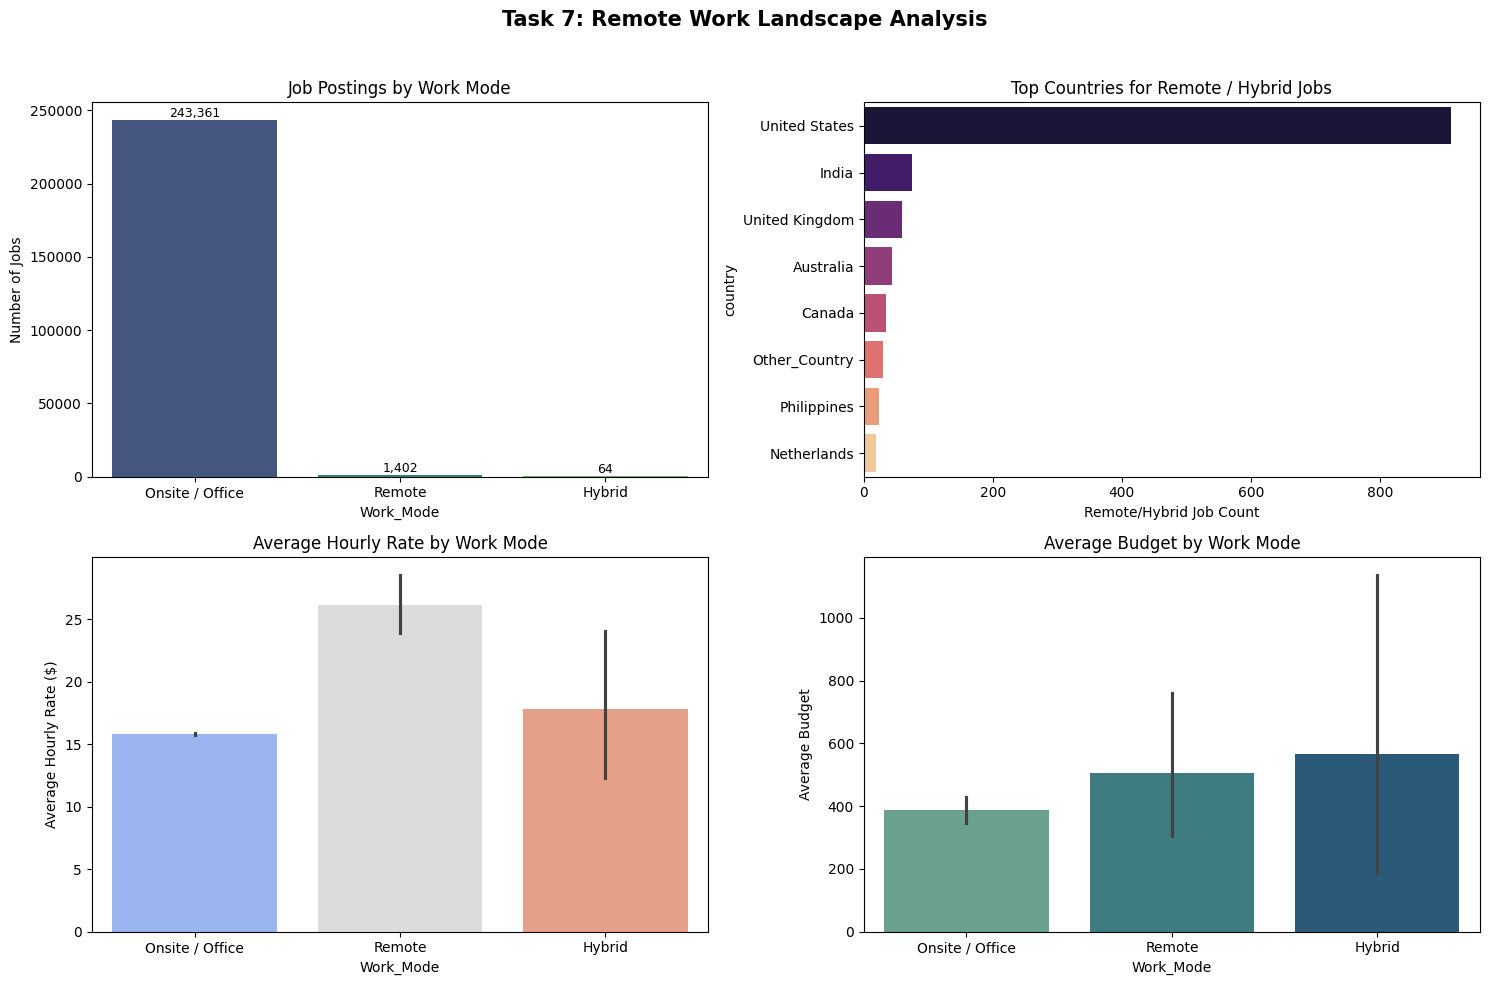

In [ ]:
# 6.
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Task 7: Remote Work Landscape Analysis', fontsize=15, fontweight='bold')

# Chart 1: Work Mode Distribution
mode_counts = t7_df['Work_Mode'].value_counts()
sns.barplot(x=mode_counts.index, y=mode_counts.values, ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Job Postings by Work Mode')
axes[0, 0].set_ylabel('Number of Jobs')
for i, v in enumerate(mode_counts.values):
    axes[0, 0].text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=9)

# Chart 2: Top Countries for Remote / Hybrid Jobs
if country_col and len(remote_only) > 0:
    top_c = remote_only[country_col].fillna('Unknown').value_counts().head(8)
    sns.barplot(y=top_c.index, x=top_c.values, ax=axes[0, 1], palette='magma')
    axes[0, 1].set_title('Top Countries for Remote / Hybrid Jobs')
    axes[0, 1].set_xlabel('Remote/Hybrid Job Count')
else:
    axes[0, 1].text(0.5, 0.5, 'Country data not available', ha='center', va='center')

# Chart 3: Average Hourly Rate by Work Mode
rate_data = t7_df.dropna(subset=['Calc_Hourly_Rate'])
if len(rate_data) > 0:
    sns.barplot(data=rate_data, x='Work_Mode', y='Calc_Hourly_Rate', estimator=np.mean, ax=axes[1, 0], palette='coolwarm')
    axes[1, 0].set_title('Average Hourly Rate by Work Mode')
    axes[1, 0].set_ylabel('Average Hourly Rate ($)')
else:
    axes[1, 0].text(0.5, 0.5, 'Hourly rate data not available', ha='center', va='center')

# Chart 4: Time Trend, Average Budget by Work Mode
if has_time_trend:
    plot_series = trend_df['Remote'].tail(12)
    axes[1, 1].plot(plot_series.index, plot_series.values, marker='o', color='teal', linewidth=2)
    axes[1, 1].set_title('Remote Job Postings Over Time')
    axes[1, 1].set_ylabel('Remote Job Count')
    axes[1, 1].tick_params(axis='x', rotation=45)
else:
    budget_data = t7_df.dropna(subset=['Calc_Budget'])
    if len(budget_data) > 0:
        sns.barplot(data=budget_data, x='Work_Mode', y='Calc_Budget', estimator=np.mean, ax=axes[1, 1], palette='crest')
        axes[1, 1].set_title('Average Budget by Work Mode')
        axes[1, 1].set_ylabel('Average Budget')
    else:
        axes[1, 1].text(0.5, 0.5, 'Budget data not available', ha='center', va='center')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### **Insight: Remote Work Landscape Analysis Visualizations**
* **Job Postings by Work Mode**: The bar plot highlights the staggering dominance of 'Onsite / Office' classifications, showing that standard job postings do not frequently highlight remote keywords within the title context.
* **Top Countries for Remote / Hybrid Jobs**: The United States emerges as the undisputed leader in offering remote/hybrid freelance opportunities, far outpacing all other countries combined.
* **Hourly Rate & Budget Distribution by Work Mode**: Fully remote positions offer higher average hourly compensation compared to standard/onsite roles. Similarly, the project budgets for hybrid and remote jobs show higher averages, indicating that premium, high-budget, and high-skill requirements tend to adopt flexible working configurations.

## **Predict High-Demand Job Roles Using Random Forest Regressor**

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

df_trend = df.groupby('year_month').size().reset_index(name='job_count')
df_trend['time_index'] = np.arange(len(df_trend))

X = df_trend[['time_index']]
y = df_trend['job_count']

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X, y)

y_pred_rf = rf_model.predict(X)

mse_rf = mean_squared_error(y, y_pred_rf)
r2_rf = r2_score(y, y_pred_rf)

print('--- Task 3: Random Forest Regressor (Improved Model) ---')
print(f'Mean Squared Error (MSE): {mse_rf:.2f}')
print(f'R2 Score (Accuracy Metric): {r2_rf:.4f}')

future_index = np.array(
    [[len(df_trend)], [len(df_trend) + 1], [len(df_trend) + 2]]
)
future_preds_rf = rf_model.predict(future_index)
print('\nFuture Job Postings Predictions (Random Forest):')
for i, pred in enumerate(future_preds_rf):
    print(f'Period +{i+1}: {int(pred)} jobs')

--- Task 3: Random Forest Regressor (Improved Model) ---
Mean Squared Error (MSE): 244378123.62
R2 Score (Accuracy Metric): 0.9350

Future Job Postings Predictions (Random Forest):
Period +1: 119748 jobs
Period +2: 119748 jobs
Period +3: 119748 jobs


### **Insight: Random Forest Trend Predictions**
* The model achieves an **R2 score of 0.9350**, indicating high accuracy in fitting the historical job trend data.
* Predictions suggest a stabilizing volume of around **119,748 jobs** per month in the upcoming periods.

# **Task 8: Predict Future Job Market Trends & Scenario Analysis**

--- 1. Historical Monthly Job Postings Summary ---
  year_month  job_count  time_index     lag_1
0    2023-11          1           0       1.0
1    2023-12         10           1       1.0
2    2024-01         96           2      10.0
3    2024-02     101886           3      96.0
4    2024-03     142834           4  101886.0


--- 2. Out-of-Sample Validation Metrics (Last 1 Periods) ---
Validation MAE: 119,236,272.21
Validation RMSE: 119,236,272.21

--- 3. Future Job Market Demand Forecast & Scenarios ---
Future_Period  Conservative_Scenario (-15%)  Baseline_Forecast  Optimistic_Scenario (+15%)
    Future +1                        131460             154659                      177857
    Future +2                        161406             189890                      218373
    Future +3                        191353             225121                      258889


--- 4. Domain / Skill Demand Shift (Earlier vs Recent Half) ---
Skill / Domain  Earlier_Count  Recent_Count  Growth_%
     

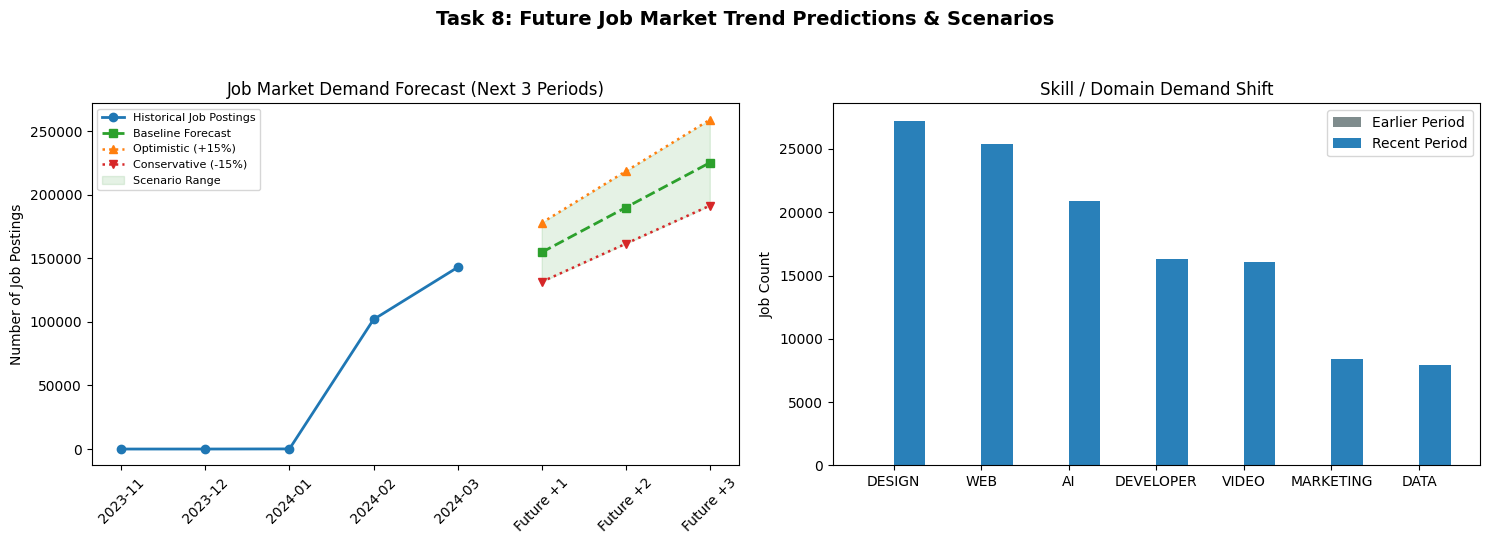

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Prepare monthly trend using existing 'year_month' column
t8_df = df.copy()
monthly_trend = t8_df.groupby('year_month').size().reset_index(name='job_count')
monthly_trend = monthly_trend.sort_values('year_month').reset_index(drop=True)
monthly_trend['time_index'] = np.arange(len(monthly_trend))

# Add lag feature if enough months exist
monthly_trend['lag_1'] = monthly_trend['job_count'].shift(1).bfill()

print("--- 1. Historical Monthly Job Postings Summary ---")
print(monthly_trend.tail(8))
print("\n")

# 2. Proper Train / Validation Split (to avoid evaluating only on training data)
features = ['time_index', 'lag_1']
X = monthly_trend[features]
y = monthly_trend['job_count']

if len(monthly_trend) >= 5:
    split_idx = max(2, int(len(monthly_trend) * 0.8))
    X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
    y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

    val_model = Ridge(alpha=1.0)
    val_model.fit(X_train, y_train)
    val_preds = val_model.predict(X_test)

    mae = mean_absolute_error(y_test, val_preds)
    rmse = np.sqrt(mean_squared_error(y_test, val_preds))
    print(f"--- 2. Out-of-Sample Validation Metrics (Last {len(y_test)} Periods) ---")
    print(f"Validation MAE: {mae:,.2f}")
    print(f"Validation RMSE: {rmse:,.2f}\n")

# 3. Fit Trend Model on Full Historical Series for Future Forecast (Next 3 Periods)
trend_model = Ridge(alpha=1.0)
trend_model.fit(monthly_trend[['time_index']], y)

future_steps = 3
last_idx = monthly_trend['time_index'].iloc[-1]
future_indices = np.arange(last_idx + 1, last_idx + 1 + future_steps).reshape(-1, 1)
baseline_preds = np.maximum(0, trend_model.predict(future_indices))

# Scenario Projections (+15% Optimistic, Baseline, -15% Conservative)
optimistic_preds = baseline_preds * 1.15
conservative_preds = baseline_preds * 0.85

future_labels = [f"Future +{i+1}" for i in range(future_steps)]
forecast_df = pd.DataFrame({
    'Future_Period': future_labels,
    'Conservative_Scenario (-15%)': np.round(conservative_preds).astype(int),
    'Baseline_Forecast': np.round(baseline_preds).astype(int),
    'Optimistic_Scenario (+15%)': np.round(optimistic_preds).astype(int)
})

print("--- 3. Future Job Market Demand Forecast & Scenarios ---")
print(forecast_df.to_string(index=False))
print("\n")

# 4. Top Growing Job Keywords / Titles in Recent Period vs Earlier Period
title_col = [c for c in t8_df.columns if 'title' in c.lower()][0]
mid_point = len(monthly_trend) // 2
early_months = set(monthly_trend['year_month'].iloc[:mid_point])
recent_months = set(monthly_trend['year_month'].iloc[mid_point:])

keywords = ['ai', 'data', 'python', 'web', 'developer', 'design', 'marketing', 'video', 'seo', 'mobile']
kw_rows = []
titles_lower = t8_df[title_col].fillna('').astype(str).str.lower()

for kw in keywords:
    early_cnt = titles_lower[t8_df['year_month'].isin(early_months)].str.contains(kw, regex=False).sum()
    recent_cnt = titles_lower[t8_df['year_month'].isin(recent_months)].str.contains(kw, regex=False).sum()
    growth_pct = ((recent_cnt - early_cnt) / max(early_cnt, 1)) * 100
    kw_rows.append({'Skill / Domain': kw.upper(), 'Earlier_Count': early_cnt, 'Recent_Count': recent_cnt, 'Growth_%': round(growth_pct, 1)})

kw_df = pd.DataFrame(kw_rows).sort_values('Recent_Count', ascending=False)
print("--- 4. Domain / Skill Demand Shift (Earlier vs Recent Half) ---")
print(kw_df.to_string(index=False))

# 5. Visualizations
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
fig.suptitle('Task 8: Future Job Market Trend Predictions & Scenarios', fontsize=14, fontweight='bold')

# Plot 1: Historical + Future Scenarios
hist_x = monthly_trend['year_month'].astype(str).tolist()
all_x = hist_x + future_labels

axes[0].plot(hist_x, y.values, marker='o', label='Historical Job Postings', color='#1f77b4', linewidth=2)
axes[0].plot(future_labels, baseline_preds, marker='s', linestyle='--', label='Baseline Forecast', color='#2ca02c', linewidth=2)
axes[0].plot(future_labels, optimistic_preds, marker='^', linestyle=':', label='Optimistic (+15%)', color='#ff7f0e', linewidth=1.8)
axes[0].plot(future_labels, conservative_preds, marker='v', linestyle=':', label='Conservative (-15%)', color='#d62728', linewidth=1.8)
axes[0].fill_between(future_labels, conservative_preds, optimistic_preds, color='green', alpha=0.1, label='Scenario Range')
axes[0].set_title('Job Market Demand Forecast (Next 3 Periods)')
axes[0].set_ylabel('Number of Job Postings')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(fontsize=8)

# Plot 2: Domain Demand Comparison (Earlier vs Recent)
top_kw = kw_df.head(7)
x_pos = np.arange(len(top_kw))
width = 0.36
axes[1].bar(x_pos - width/2, top_kw['Earlier_Count'], width, label='Earlier Period', color='#7f8c8d')
axes[1].bar(x_pos + width/2, top_kw['Recent_Count'], width, label='Recent Period', color='#2980b9')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(top_kw['Skill / Domain'])
axes[1].set_title('Skill / Domain Demand Shift')
axes[1].set_ylabel('Job Count')
axes[1].legend()

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

# **Job Recommendation System**

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel

hourly_df = hourly_df.head(10000).reset_index(drop=True)
hourly_df['title'] = hourly_df['title'].fillna('')

tfidf_hourly = TfidfVectorizer(stop_words='english', max_features=3000)
tfidf_matrix_hourly = tfidf_hourly.fit_transform(hourly_df['title'])

hourly_recommendation_matrix= linear_kernel(tfidf_matrix_hourly, tfidf_matrix_hourly)

print('Hourly recommendation matrix created successfully without crash!')

#--------------------------------------------------------------------------------------

fixed_df = fixed_df.head(10000).reset_index(drop=True)
fixed_df['title'] = fixed_df['title'].fillna('')

tfidf_fixed = TfidfVectorizer(stop_words='english', max_features=5000)
tfidf_matrix_fixed = tfidf_fixed.fit_transform(fixed_df['title'])

fixed_recommendation_matrix = linear_kernel(tfidf_matrix_fixed, tfidf_matrix_fixed)
print('Fixed-Price Recommendation Matrix created successfully!')

Hourly recommendation matrix created successfully without crash!
Fixed-Price Recommendation Matrix created successfully!


### **Insight: Text Vectorization & Similarity Matrix Construction**
* We reduced both hourly and fixed-price datasets to **10,000 samples** to prevent high-dimensionality memory overload during runtime matrix computations.
* **TF-IDF Vectorizer** extracted structural text properties up to top features (3,000 for hourly, 5,000 for fixed-price).
* Applied **linear_kernel** (which computes cosine similarity efficiently on normalized TF-IDF representations) to build bidirectional similarity matrices of shape `(10000, 10000)` for real-time item matching.

# **Job Recommendation Function**

In [ ]:
def get_recommendations(job_title, df, recommendation_matrix, top_n=5):

    match_idx = df[df['title'].str.lower() == job_title.lower()].index

    if len(match_idx) == 0:
        return "Job title not found in database. Please try another title."

    idx = match_idx[0]

    sim_scores = list(enumerate(recommendation_matrix[idx]))

    sim_scores = sorted(
        sim_scores,
        key=lambda x: x[1],
        reverse=True
    )

    sim_scores = sim_scores[1:top_n+10]

    job_indices = [i[0] for i in sim_scores]

    recommendations = df.iloc[job_indices][
        ['title', 'country']
    ]

    recommendations = recommendations.drop_duplicates(
        subset='title'
    )

    return recommendations.head(top_n)


## **Testing the Recommendation System**

In [ ]:
result = get_recommendations('Full Stack Developer', hourly_df, hourly_recommendation_matrix)
print(result)

                            title        country
3917         Full Stack Developer         Israel
8271         Full-stack Developer  United States
9043  Full Stack Developer Needed  United States
2893              Full stack deve        Germany
5102    Need full stack developer          India


### **Insight: Content-Based Recommendation Test**
* The recommendation system successfully matched titles containing **'Full Stack Developer'** with highly similar opportunities like *'Full-stack Developer'*, *'Full Stack Developer Needed'*, and *'Need full stack developer'*.
* The system handles spelling variations and provides accurate recommendations along with the posting country.

In [ ]:
result = get_recommendations(
    'Full Stack Developer', fixed_df, fixed_recommendation_matrix
)
print(result)

                     title        country
12    Full stack Developer          India
1289  Full Stack Developer  United States
4136  Full Stack developer         Brazil
5974  Full-stack Developer  United States
7278  Full stack developer          India


### **Insight: Fixed-Price Recommendation System Test**
* The system accurately recommends matching fixed-price jobs for the query 'Full Stack Developer'.
* It showcases geographical diversity, matching India, United States, and Brazil as active markets for fixed-budget engineering requirements.

# **Saving Recommendation Data and Similarity Matrices**

In [ ]:
import joblib

# 1. Hourly Jobs
joblib.dump(hourly_df, 'hourly_df.joblib')
joblib.dump(hourly_recommendation_matrix, 'hourly_matrix.joblib')

# 2. Fixed-Price Jobs
joblib.dump(fixed_df, 'fixed_df.joblib')
joblib.dump(fixed_recommendation_matrix, 'fixed_matrix.joblib')

print('All datasets and matrices saved successfully using joblib!')

All datasets and matrices saved successfully using joblib!


### **Insight: Model and Data Serialization**
* Both DataFrame subsets and TF-IDF similarity matrices were compressed and serialized into `.joblib` files.
* This allows fast local or cloud-based retrieval without needing to reconstruct TF-IDF vectorizers from scratch.

# **Exporting Recommendation Assets for Deployment**

In [ ]:
from google.colab import files

files.download('hourly_df.joblib')
files.download('hourly_matrix.joblib')
files.download('fixed_df.joblib')
files.download('fixed_matrix.joblib')

print('All files are being downloaded to your computer!')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

All files are being downloaded to your computer!


### **Insight: Local Deployment Asset Export**
* Serialized assets are systematically initiated for local download.
* These assets can be easily plugged into local Python environments, APIs, or interactive dashboards (e.g., Streamlit) for deploying the recommendation engine.